<a href="https://colab.research.google.com/github/Cintya-rdev/ml-primeiro-modelo/blob/main/2026_11_14_v0_1_pipeline_bioh2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Importação das Bibliotecas



In [8]:
# BLOCO 1: Importação das bibliotecas essenciais da Fase 1
import pandas as pd   # Manipulação de tabelas (DataFrames)
import numpy as np    # Operações matemáticas e geração de números

print("Ambiente Python do Colab pronto! Versão do Pandas:", pd.__version__)

Ambiente Python do Colab pronto! Versão do Pandas: 2.2.3


2. Geração do Dataset Provisório em Batelada (250 ensaios)

In [9]:
# BLOCO 2: Geração do Dataset Provisório em Batelada (250 ensaios)
np.random.seed(42) # Trava a semente aleatória para dar sempre os mesmos números
n = 250            # Número de frascos/ensaios simulados

# Criando a tabela (DataFrame) com as 11 variáveis pré-aprovadas (X01 a X11)
df_bruto = pd.DataFrame({
    # 3 Variáveis Categóricas (Texto)
    'x01_substrato': np.random.choice(['vinhaca', 'glicerol', 'lignocelulosico', 'efluentes'], n),
    'x02_origem_inoculo': np.random.choice(['lodo_uasb', 'lodo_ete', 'ruminal', 'consorcio_misto'], n),
    'x11_pre_tratamento': np.random.choice(['nenhum', 'termico', 'acido', 'alcalino'], n),

    # 8 Variáveis Numéricas Contínuas (Números)
    'x03_art_g_l': np.random.uniform(5.0, 40.0, n),               # Açúcares Redutores Totais (g/L)
    'x04_relacao_inoculo_substrato': np.random.uniform(0.5, 3.0, n), # g SV / g DQO
    'x05_conc_inoculo_g_l': np.random.uniform(2.0, 15.0, n),      # Concentração de inóculo (g/L)
    'x06_ph_inicial': np.random.uniform(4.5, 7.5, n),             # pH inicial
    'x07_temperatura_c': np.random.uniform(30.0, 55.0, n),        # Temperatura (°C)
    'x08_tempo_fermentacao_h': np.random.uniform(12.0, 72.0, n),  # Tempo de batelada (h)
    'x09_volume_reator_l': np.random.choice([0.1, 0.25, 0.5, 1.0], n), # Volume do frasco (L)
    'x10_volume_headspace_l': np.random.choice([0.05, 0.1, 0.2, 0.4], n) # Headspace (L)
})

# Simulando o Alvo (y): Rendimento de H2 (mL/g) com ótimo biológico perto de pH 5.8 e 37°C
efeito_ph = -8.0 * (df_bruto['x06_ph_inicial'] - 5.8)**2
efeito_temp = -0.15 * (df_bruto['x07_temperatura_c'] - 37.0)**2
ruido = np.random.normal(0, 3.0, n)

df_bruto['y_rendimento_h2_ml_g'] = (
    45.0
    + 0.6 * df_bruto['x03_art_g_l']
    + 4.0 * df_bruto['x04_relacao_inoculo_substrato']
    + efeito_ph
    + efeito_temp
    + ruido
).clip(lower=5.0) # Garante que não exista rendimento negativo

# Inserindo 10 falhas de medição APENAS em análises laboratoriais de bancada (ART e Sólidos do Inóculo)
indices_nulos = np.random.choice(df_bruto.index, size=10, replace=False)
df_bruto.loc[indices_nulos[:5], 'x03_art_g_l'] = np.nan
df_bruto.loc[indices_nulos[5:], 'x05_conc_inoculo_g_l'] = np.nan

df_bruto.head() # Visualizando as 5 primeiras linhas da nossa tabela




,x01_substrato,x02_origem_inoculo,x11_pre_tratamento,x03_art_g_l,x04_relacao_inoculo_substrato,x05_conc_inoculo_g_l,x06_ph_inicial,x07_temperatura_c,x08_tempo_fermentacao_h,x09_volume_reator_l,x10_volume_headspace_l,y_rendimento_h2_ml_g
0,lignocelulosico,lodo_ete,acido,16.164147,1.422284,4.029984,6.152572,51.768748,53.400293,0.5,0.4,30.121983
1,efluentes,lodo_uasb,nenhum,34.570636,1.656337,11.307639,4.760960,41.132631,24.056021,0.1,0.2,65.466130
2,vinhaca,consorcio_misto,nenhum,5.814518,2.368677,10.566011,5.725360,42.870434,44.149661,0.1,0.2,49.182518
3,lignocelulosico,lodo_uasb,alcalino,33.506397,0.591708,2.352248,5.618066,38.980834,17.800587,0.1,0.2,65.851558
4,lignocelulosico,lodo_uasb,acido,14.864917,1.131092,4.885638,5.279261,44.823771,39.022256,1.0,0.4,47.190434


3. Análise Exploratória dos Dados (EDA)

In [10]:
# BLOCO 3: Análise Exploratória dos Dados (EDA)

# 1. Verificar dimensões (linhas, colunas)
print(f"Dimensões do Dataset: {df_bruto.shape[0]} ensaios (linhas) e {df_bruto.shape[1]} colunas.\n")

# 2. Contar quantos valores ausentes (NaN) existem em cada coluna
print("--- Contagem de Valores Ausentes (Nulos) por Variável ---")
print(df_bruto.isnull().sum())
print("\n" + "="*60 + "\n")

# 3. Estatísticas descritivas das variáveis numéricas (arredondado para 2 casas decimais)
print("--- Resumo Estatístico das Variáveis Numéricas ---")
display(df_bruto.describe().round(2))

Dimensões do Dataset: 250 ensaios (linhas) e 12 colunas.

--- Contagem de Valores Ausentes (Nulos) por Variável ---
x01_substrato                    0
x02_origem_inoculo               0
x11_pre_tratamento               0
x03_art_g_l                      5
x04_relacao_inoculo_substrato    0
x05_conc_inoculo_g_l             5
x06_ph_inicial                   0
x07_temperatura_c                0
x08_tempo_fermentacao_h          0
x09_volume_reator_l              0
x10_volume_headspace_l           0
y_rendimento_h2_ml_g             0
dtype: int64


--- Resumo Estatístico das Variáveis Numéricas ---


,x03_art_g_l,x04_relacao_inoculo_substrato,x05_conc_inoculo_g_l,x06_ph_inicial,x07_temperatura_c,x08_tempo_fermentacao_h,x09_volume_reator_l,x10_volume_headspace_l,y_rendimento_h2_ml_g
count,245.00,250.00,245.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,23.13,1.71,8.50,6.03,42.42,42.32,0.47,0.20,47.15
std,10.72,0.70,3.91,0.88,7.10,17.83,0.35,0.14,16.66
min,5.38,0.51,2.14,4.52,30.12,12.66,0.10,0.05,5.00
25%,13.66,1.11,5.01,5.23,36.12,26.15,0.25,0.10,37.51
50%,23.31,1.67,8.66,6.12,42.88,42.47,0.25,0.20,49.87
75%,33.12,2.32,12.02,6.77,47.71,58.16,1.00,0.40,59.09
max,39.99,2.99,14.93,7.49,54.99,71.80,1.00,0.40,80.36


4.
Separação X / y e Divisão Holdout (80% Treino / 20% Teste)

In [11]:
# BLOCO 4: Separação X / y e Divisão Holdout (80% Treino / 20% Teste)
from sklearn.model_selection import train_test_split

# 1. Separar quem são as variáveis explicativas (X) e quem é o alvo a prever (y)
X = df_bruto.drop(columns=['y_rendimento_h2_ml_g']) # Todas as 11 colunas de entrada
y = df_bruto['y_rendimento_h2_ml_g']                # Apenas a coluna de rendimento de H2

# 2. Dividir em 80% Treino e 20% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,    # Reserva 20% para o teste cego
    random_state=42    # Semente fixa para a divisão ser sempre igual
)

print(f"Conjunto de Treino (80%): {X_train.shape[0]} ensaios para o modelo estudar.")
print(f"Conjunto de Teste  (20%): {X_test.shape[0]} ensaios trancados para avaliação final.")

Conjunto de Treino (80%): 200 ensaios para o modelo estudar.
Conjunto de Teste  (20%): 50 ensaios trancados para avaliação final.


5. Pré-processamento sem Vazamento de Dados (ColumnTransformer)


In [12]:
# BLOCO 5: Pré-processamento sem Vazamento de Dados (ColumnTransformer)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separar os nomes das colunas por tipo (3 Categóricas e 8 Numéricas)
colunas_categoricas = [
    'x01_substrato',
    'x02_origem_inoculo',
    'x11_pre_tratamento'
]

colunas_numericas = [
    'x03_art_g_l',
    'x04_relacao_inoculo_substrato',
    'x05_conc_inoculo_g_l',
    'x06_ph_inicial',
    'x07_temperatura_c',
    'x08_tempo_fermentacao_h',
    'x09_volume_reator_l',
    'x10_volume_headspace_l'
]

# 2. Criar a regra para variáveis NUMÉRICAS:
# Passo A: Preencher falhas laboratoriais (ART ou Inóculo) com a mediana do treino
# Passo B: Padronizar escalas (média = 0, desvio padrão = 1)
regra_numerica = Pipeline(steps=[
    ('imputador_mediana', SimpleImputer(strategy='median')),
    ('escalonador_padrao', StandardScaler())
])

# 3. Criar a regra para variáveis CATEGÓRICAS (Substrato, Inóculo, Pré-tratamento):
# Transforma texto em colunas binárias (0 e 1) e ignora categorias desconhecidas no futuro
regra_categorica = Pipeline(steps=[
    ('codificador_onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Unir as duas regras no ColumnTransformer
preprocessador = ColumnTransformer(transformers=[
    ('num', regra_numerica, colunas_numericas),
    ('cat', regra_categorica, colunas_categoricas)
])

# Visualizar a arquitetura do pré-processador
preprocessador

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputador_mediana',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonador_padrao',
                                                  StandardScaler())]),
                                 ['x03_art_g_l',
                                  'x04_relacao_inoculo_substrato',
                                  'x05_conc_inoculo_g_l', 'x06_ph_inicial',
                                  'x07_temperatura_c',
                                  'x08_tempo_fermentacao_h',
                                  'x09_volume_reator_l',
                                  'x10_volume_headspace_l']),
                                ('cat',
                                 Pipeline(steps=[('codificador_onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['x01_substrato', 'x02_origem_inoculo',
                                  'x11_pre_tratamento'])])

6: Modelo na Pipeline e Treinanamento

In [13]:
# BLOCO 6: Acoplamento Modelo + Preprocessador e Treinamento
from sklearn.ensemble import RandomForestRegressor

# 1. Criar a Pipeline Completa (Preprocessador + Algoritmo)
pipeline_v01 = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo_rf', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 2. Treinar a pipeline APENAS com os 200 ensaios de treino (80%)
# Aqui ela aprende a mediana, a escala, as categorias e treina as 100 árvores!
pipeline_v01.fit(X_train, y_train)

# 3. Fazer a previsão cega nos 50 ensaios de teste (20%) que estavam trancados
y_pred = pipeline_v01.predict(X_test)

# Mostrar uma comparação rápida dos 5 primeiros ensaios do teste (Real vs. Previsto)
comparacao = pd.DataFrame({
    'Y_Real (mL/g)': y_test.values[:5].round(2),
    'Y_Predito (mL/g)': y_pred[:5].round(2),
    'Erro / Resíduo (mL/g)': (y_test.values[:5] - y_pred[:5]).round(2)
})
display(comparacao)

,Y_Real (mL/g),Y_Predito (mL/g),Erro / Resíduo (mL/g)
0,37.49,26.93,10.55
1,77.52,59.88,17.64
2,21.48,17.36,4.12
3,46.57,55.55,-8.98
4,44.73,38.32,6.41


7. Avaliação de Desempenho, Gráficos e Salvamento

=== DESEMPENHO DO MODELO (CONJUNTO DE TESTE - 20%) ===
MAE  (Erro Médio Absoluto):      4.32 mL H2/g
RMSE (Raiz do Erro Quadrático):  5.63 mL H2/g
R²   (Coeficiente Determinação): 0.8455 (84.6% da variância explicada)



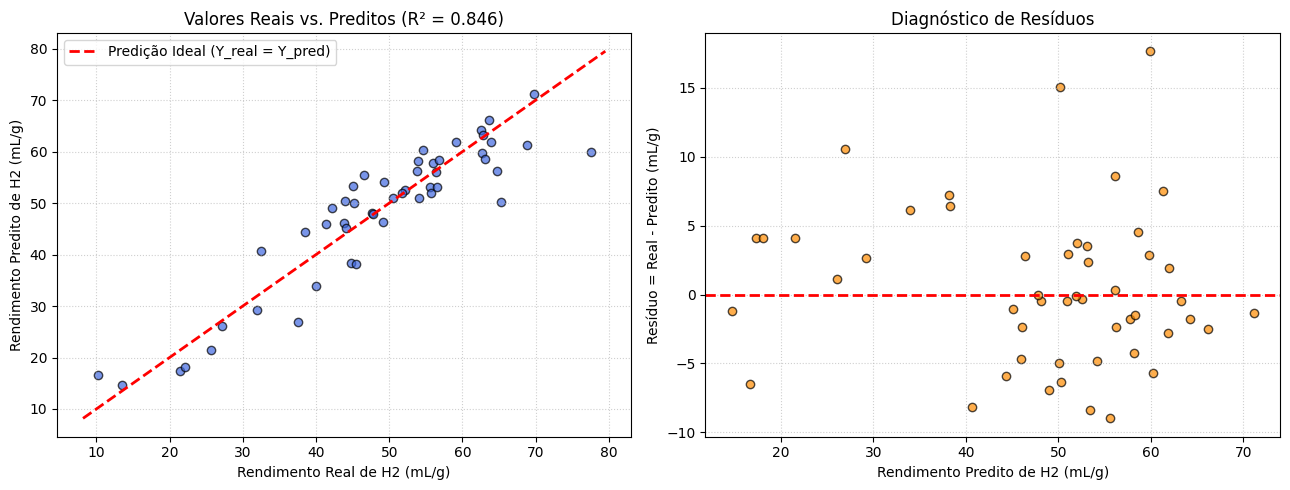

Modelo salvo com sucesso como 'pipeline_bioh2_v01.joblib'!


In [14]:
# BLOCO 7: Métricas de Avaliação, Diagnóstico de Resíduos e Exportação
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import joblib

# 1. Calcular as métricas no conjunto de teste
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== DESEMPENHO DO MODELO (CONJUNTO DE TESTE - 20%) ===")
print(f"MAE  (Erro Médio Absoluto):      {mae:.2f} mL H2/g")
print(f"RMSE (Raiz do Erro Quadrático):  {rmse:.2f} mL H2/g")
print(f"R²   (Coeficiente Determinação): {r2:.4f} ({r2*100:.1f}% da variância explicada)\n")

# 2. Plotar os dois gráficos lado a lado (Predito vs Real e Mapa de Resíduos)
residuos = y_test - y_pred
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Real vs Predito
ax1.scatter(y_test, y_pred, alpha=0.7, edgecolors='k', color='royalblue')
limites = [min(y_test.min(), y_pred.min()) - 2, max(y_test.max(), y_pred.max()) + 2]
ax1.plot(limites, limites, 'r--', lw=2, label='Predição Ideal (Y_real = Y_pred)')
ax1.set_xlabel('Rendimento Real de H2 (mL/g)')
ax1.set_ylabel('Rendimento Predito de H2 (mL/g)')
ax1.set_title(f'Valores Reais vs. Preditos (R² = {r2:.3f})')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico 2: Diagnóstico de Resíduos
ax2.scatter(y_pred, residuos, alpha=0.7, edgecolors='k', color='darkorange')
ax2.axhline(0, color='r', linestyle='--', lw=2)
ax2.set_xlabel('Rendimento Predito de H2 (mL/g)')
ax2.set_ylabel('Resíduo = Real - Predito (mL/g)')
ax2.set_title('Diagnóstico de Resíduos')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('diagnostico_v01.png', dpi=300)
plt.show()

# 3. Exportar a pipeline completa treinada
joblib.dump(pipeline_v01, 'pipeline_bioh2_v01.joblib')
print("Modelo salvo com sucesso como 'pipeline_bioh2_v01.joblib'!")
